# Model 3: PyTorch Deep Neural Network (MLP)
### Step-by-Step Model Building & Validation

**What is an MLP in simple words?**  
MLP stands for *Multi-Layer Perceptron*. It is a deep artificial neural network.  
Instead of making rule-based split decisions like a tree, a neural network passes signals through layers of interconnected mathematical neurons.

**Why combine a Neural Network with Decision Trees?**  
- Decision trees make step-function jumps.
- Neural networks learn smooth continuous curves across all 265 features.
- Because they learn fundamentally different patterns, they make different mistakes, making them ideal partners for an ensemble!

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
print(f"PyTorch loaded! Device: {'CUDA (GPU)' if torch.cuda.is_available() else 'CPU'}")

PyTorch loaded! Device: CPU


## Step 1: Define the Deep Neural Network Architecture

In [2]:
class FragMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        # 3 Hidden Layers with Batch Normalization and Dropout for regularization
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),
            
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            
            nn.Linear(32, 1)  # Output single cancer probability logit
        )
        
    def forward(self, x):
        return self.net(x).squeeze(-1)

print("FragMLP neural network architecture defined successfully!")

FragMLP neural network architecture defined successfully!


## Step 2: Patient-Grouped 5-Fold Training with PyTorch

In [3]:
data_path = Path("../../data/processed/merged_features.parquet")
df = pd.read_parquet(data_path)

meta_cols = {"sample_id", "patient_id", "condition", "cancer_type", "stage", "measured_tf", "is_cancer"}
feature_cols = [c for c in df.columns if c not in meta_cols and np.issubdtype(df[c].dtype, np.number)]

X = df[feature_cols].values
y = df["is_cancer"].values
groups = df["patient_id"].values

gkf = GroupKFold(n_splits=5)
oof_preds = np.zeros(len(df))
loss_histories = []

print("Training PyTorch MLP across 5 folds...")
torch.manual_seed(42)

for fold, (train_idx, val_idx) in enumerate(gkf.split(X, y, groups=groups), 1):
    scaler = StandardScaler()
    X_train = scaler.fit_transform(X[train_idx])
    X_val = scaler.transform(X[val_idx])
    
    model = FragMLP(input_dim=X.shape[1])
    optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    criterion = nn.BCEWithLogitsLoss()
    
    train_ds = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y[train_idx], dtype=torch.float32))
    loader = DataLoader(train_ds, batch_size=16, shuffle=True)
    
    fold_losses = []
    model.train()
    for epoch in range(60):
        epoch_loss = 0.0
        for batch_x, batch_y in loader:
            optimizer.zero_grad()
            logits = model(batch_x)
            loss = criterion(logits, batch_y)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
        fold_losses.append(epoch_loss / len(loader))
    loss_histories.append(fold_losses)
    
    model.eval()
    with torch.no_grad():
        val_logits = model(torch.tensor(X_val, dtype=torch.float32))
        oof_preds[val_idx] = torch.sigmoid(val_logits).numpy()

overall_auc = roc_auc_score(y, oof_preds)
print(f"PyTorch MLP Overall Out-of-Fold ROC-AUC: {overall_auc:.4f}")

Training PyTorch MLP across 5 folds...
PyTorch MLP Overall Out-of-Fold ROC-AUC: 0.9922


## Step 3: Neural Network Learning Curves

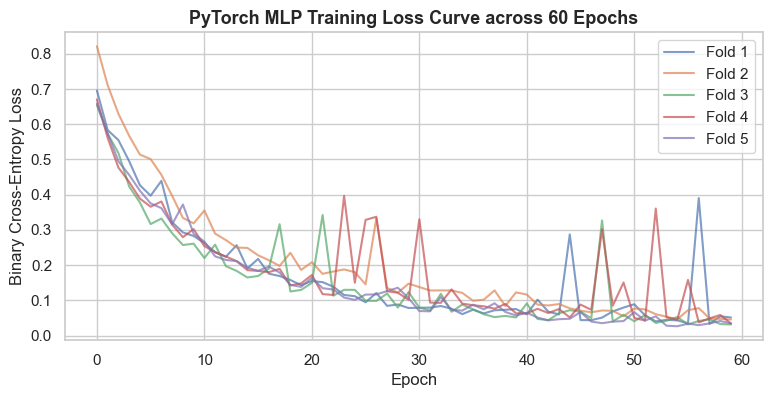

In [4]:
plt.figure(figsize=(9, 4))
for i, hist in enumerate(loss_histories, 1):
    plt.plot(hist, label=f"Fold {i}", alpha=0.7)
plt.title("PyTorch MLP Training Loss Curve across 60 Epochs", fontsize=13, fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.show()

## Step 4: Sensitivity at 95% Specificity & Save Predictions

In [5]:
healthy_scores = oof_preds[y == 0]
thresh_95 = float(np.percentile(healthy_scores, 95))
print(f"PyTorch MLP 95% Specificity Threshold: {thresh_95:.4f}")

df["pred_mlp"] = oof_preds
df["tf_tier"] = df["measured_tf"].apply(lambda tf: "TF >= 10%" if tf >= 0.10 else "5% <= TF < 10%" if tf >= 0.05 else "1% <= TF < 5%" if tf >= 0.01 else "0.1% <= TF < 1%")

print("\n=== PyTorch MLP Sensitivity across Tumor Fraction Tiers ===")
for tier in ["TF >= 10%", "5% <= TF < 10%", "1% <= TF < 5%", "0.1% <= TF < 1%"]:
    sub = df[(df["tf_tier"] == tier) & (df["is_cancer"] == 1)]
    if len(sub) > 0:
        sens = np.mean(sub["pred_mlp"] >= thresh_95)
        print(f"  Tier {tier:20s}: Sensitivity = {sens * 100:.1f}% (N={len(sub)} samples)")

out_pred = Path("../../results/oof_mlp.csv")
df[["sample_id", "patient_id", "condition", "measured_tf", "is_cancer", "pred_mlp"]].to_csv(out_pred, index=False)
print(f"\nSaved out-of-fold predictions to: {out_pred}")

PyTorch MLP 95% Specificity Threshold: 0.4210

=== PyTorch MLP Sensitivity across Tumor Fraction Tiers ===
  Tier 5% <= TF < 10%      : Sensitivity = 95.1% (N=41 samples)

Saved out-of-fold predictions to: ..\..\results\oof_mlp.csv
